# Set-Up

In [1]:
# Load libraries

%pip install xlrd shapely

import geopandas as gpd
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import pyreadr as pyr
import xlrd


Defaulting to user installation because normal site-packages is not writeable
  Using cached xlrd-2.0.2-py2.py3-none-any.whl.metadata (3.5 kB)
Using cached xlrd-2.0.2-py2.py3-none-any.whl (96 kB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Load data bases

# 2000
try:
    m1 = gpd.read_file(r'Dados/Demografia/2000/3303302.SHP')
    c1 = pd.read_excel(r'Dados/Demografia/2000/Censo/Pessoa1_RJ.XLS') 
        # V1330 represents the sum of people in the census area
    print('2000 loaded')
except Exception as e:
    print(f'Error - 2000: {e}')

# 2010
try:
    m2 = gpd.read_file(r'Dados/Demografia/2010/33SEE250GC_SIR.shp')
    c2 = pd.read_excel(r'Dados/Demografia/2010/Base informaçoes setores2010 universo RJ/EXCEL/Pessoa01_RJ.xls')
    print('2010 loaded')
except Exception as e:
    print(f'Error - 2010: {e}')
 
# 2022
try:
    m3 = gpd.read_file(r'Dados/RJ_setores_CD2022.gpkg')
    c3 = pd.read_csv(r'Dados/Demografia/2022/Agregados_por_setores_demografia_BR.csv', sep=';',
                    low_memory = False)
    print('2022 loaded')
except Exception as e:
    print(f'Error - 2022: {e}')


/tmp/ipykernel_83738/710126077.py:6: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  c1 = pd.read_excel(r'Dados/Demografia/2000/Censo/Pessoa1_RJ.XLS')


WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
2000 loaded


/tmp/ipykernel_83738/710126077.py:15: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  c2 = pd.read_excel(r'Dados/Demografia/2010/Base informaçoes setores2010 universo RJ/EXCEL/Pessoa01_RJ.xls')


2010 loaded
2022 loaded


# Minimum Common Area

In [ ]:
# Rename ids for 2000 db
if 'ID_' in m1.columns:
    m1 = m1.rename(columns={'ID_': 'id_2000'})
    print('m1 id column renamed')
else:
    print('m1 unmodified')

# Filter city for 2010 db
if 'CD_GEOCODI' in m2.columns:
    m2 = m2[m2['NM_MUNICIP'] == 'NITERÓI']
    m2 = m2 = m2.rename(columns={'CD_GEOCODI': 'id_2010'})
    print('m2 id column renamed')
else:
    print('m2 unmodified')

# Filter city for 2022 db
if 'CD_SETOR' in m3.columns:
    m3 = m3.rename(columns= {'CD_SETOR': 'id_2022'})
    m3 = m3[m3['NM_MUN'] == 'Niterói']
    print('m3 id column renamed')
else:
    print('m3 unmodified')


# Adjust Projection for geometry
EPSG_UTM = 31983  # SIRGAS 2000 UTM Zone 23S

m1 = m1[["id_2000", "geometry"]].set_crs(epsg=32723, allow_override=True).to_crs(epsg=EPSG_UTM)

m2 = m2[["id_2010", "geometry"]].to_crs(epsg=EPSG_UTM)
m3 = m3[["id_2022", "geometry"]].to_crs(epsg=EPSG_UTM)

if (m1.crs == m2.crs) & (m1.crs == m3.crs):
    print('crs ok')
else:
    print('crs NOT ok')



m1 unmodified
m2 unmodified
m3 unmodified
crs: ok


In [9]:
# Clean DBs

m1 = m1[["id_2000", "geometry"]]
m2 = m2[["id_2010", "geometry"]]
m3 = m3[["id_2022", "geometry"]]

m1.geometry = m1.geometry.buffer(0)
m2.geometry = m2.geometry.buffer(0)
m3.geometry = m3.geometry.buffer(0)


In [ ]:
# 2010 x 2000
its1 = gpd.overlay(m2 , m1, how = 'intersection')
its1['area'] = its1.geometry.area

idw = its1.groupby('id_2010')['area'].idxmax()
w = its1.loc[idw]

dic = dict(zip(w['id_2010'], w['id_2000']))

# 2022 x 2010
its2 = gpd.overlay(m3, m2, how = 'intersection')
its2['area'] = its2.geometry.area

idw1 = its2.groupby('id_2022')['area'].idxmax()
w1 = its2.loc[idw1]

dic1 = dict(zip(w1['id_2022'], w1['id_2010']))

# AMC
dic3 = {}
for id_2022, id_2010 in dic1.items():
    id_original = dic.get(id_2010)
    if id_original:
        dic3[id_2022] = id_original
    else:
        dic3[id_2022] = id_2010

m1['id_amc'] = m1['id_2000']
m2['id_amc'] = m2['id_2010'].map(dic).fillna(m2['id_2010'])
m3['id_amc'] = m3['id_2022'].map(dic3).fillna(m3['id_2022'])

amc = m3.dissolve(by = 'id_amc').reset_index()


<Axes: >

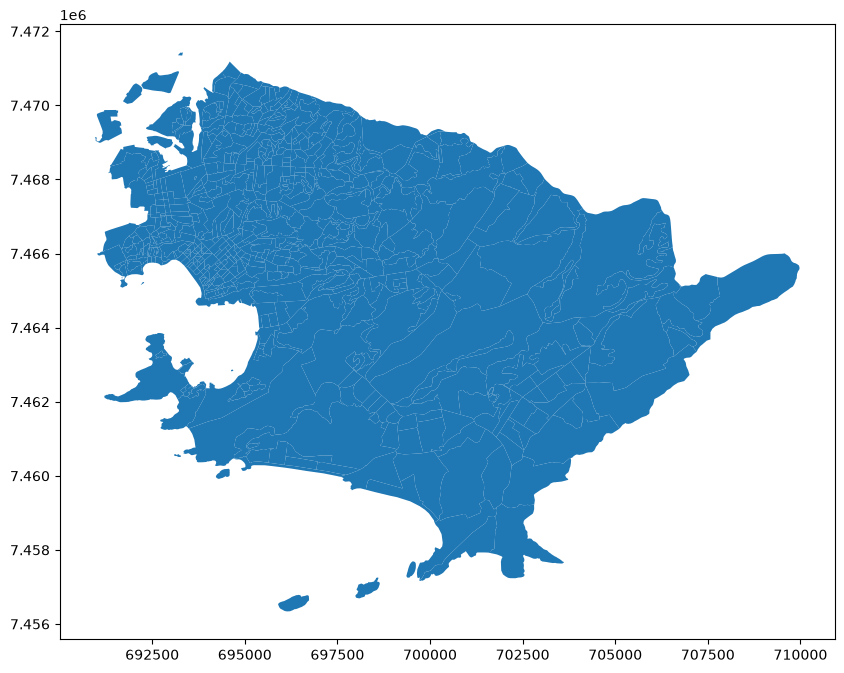

In [11]:
fig, ax = plt.subplots(figsize = (10, 10))
amc.plot(
    ax=ax)


# Merge

In [12]:
for c in [c1, c2, c3]:
    print(f'keys: {c.keys()}',
          ' ',
          ' -----------------------------------------------------------------',
          sep = '\n')


keys: Index(['Cod_setor', 'Situacao', 'Tipo_do_setor', 'V1330', 'V1331', 'V1332',
       'V1333', 'V1334', 'V1335', 'V1336',
       ...
       'V1455', 'V1456', 'V1457', 'V1458', 'V1459', 'V1460', 'V1461', 'V1462',
       'V1463', 'V1464'],
      dtype='str', length=138)
 
 -----------------------------------------------------------------
keys: Index(['Cod_setor', 'Situacao_setor', 'V001', 'V002', 'V003', 'V004', 'V005',
       'V006', 'V007', 'V008', 'V009', 'V010', 'V011', 'V012', 'V013', 'V014',
       'V015', 'V016', 'V017', 'V018', 'V019', 'V020', 'V021', 'V022', 'V023',
       'V024', 'V025', 'V026', 'V027', 'V028', 'V029', 'V030', 'V031', 'V032',
       'V033', 'V034', 'V035', 'V036', 'V037', 'V038', 'V039', 'V040', 'V041',
       'V042', 'V043', 'V044', 'V045', 'V046', 'V047', 'V048', 'V049', 'V050',
       'V051', 'V052', 'V053', 'V054', 'V055', 'V056', 'V057', 'V058', 'V059',
       'V060', 'V061', 'V062', 'V063', 'V064', 'V065', 'V066', 'V067', 'V068',
       'V069', 'V070',

In [13]:
# Rename id columns

c1 = c1.rename(columns = {'Cod_setor': 'id_2000', 'V1330': 'pop'})
c1['pop'] = pd.to_numeric(c1['pop'], errors = 'coerce')
c1['id_2000'] = c1['id_2000'].astype(str)

c2 = c2.rename(columns = {'Cod_setor': 'id_2010', 'V030': 'pop'})
c2['pop'] = pd.to_numeric(c2['pop'], errors = 'coerce')
c2['id_2010'] = c2['id_2010'].astype(str)

c3 = c3.rename(columns = {'CD_setor' : 'id_2022', 'V01006': 'pop'})
c3['pop'] = pd.to_numeric(c3['pop'], errors = 'coerce')
c3['id_2022'] = c3['id_2022'].astype(str)


In [14]:
g1 = m1.merge(c1, on = 'id_2000')
g2 = m2.merge(c2, on = 'id_2010')
g3 = m3.merge(c3, on = 'id_2022')

db1 = (g1.groupby('id_amc')['pop'].sum().reset_index())
db1['year'] = 2000
db1 = amc[['id_amc', 'geometry']].merge(
    db1,
    on='id_amc',
    how='left'
)

db2 = (g2.groupby('id_amc')['pop'].sum().reset_index())
db2['year'] = 2010
db2 = amc[['id_amc', 'geometry']].merge(
    db2,
    on='id_amc',
    how='left'
)

db3 = (g3.groupby('id_amc')['pop'].sum().reset_index())
db3['year'] = 2022
db3 = amc[['id_amc', 'geometry']].merge(
    db3,
    on='id_amc',
    how='left'
)

db = pd.concat(
    [db1, db2, db3],
    ignore_index=True
)


In [15]:
db['area'] = db.geometry.area
db['density'] = db['pop']/db['area']
db = db.set_geometry('geometry')


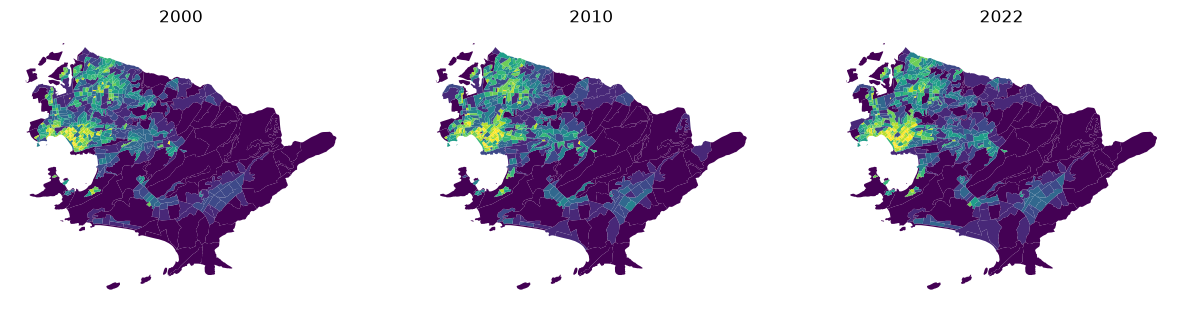

In [16]:
fig, ax = plt.subplots(1, 3, figsize = (15,10))

x = 0
for year in [2000, 2010, 2022]:
    db[db['year'] == year].plot(column = 'density',
                                ax = ax[x],
                                scheme = 'quantiles',
                                k = 10)
    ax[x].set_title(str(year))
    ax[x].axis('off')
    x = x + 1


# Create artificial density values for years inbetween

In [17]:
ids = db['id_amc'].unique()

years = pd.DataFrame(
    [(i, y) for i in ids for y in range(2000, 2023)],
    columns=['id_amc', 'year']
)

db = years.merge(
    db.drop(columns='geometry', errors='ignore'),
    on=['id_amc', 'year'],
    how='left'
)

db = db.sort_values(['id_amc', 'year'])

db['density'] = (
    db.groupby('id_amc')['density']
      .transform(lambda x: x.interpolate())
)

db = db.merge(
    amc[['id_amc', 'geometry']],
    on='id_amc',
    how='left'
)

db = gpd.GeoDataFrame(
    db,
    geometry='geometry',
    crs=amc.crs
)


In [18]:
db = db[['id_amc', 'year', 'density', 'area', 'geometry']]


In [19]:
valid = range(2009, 2024)

db = db[db['year'].isin(valid)]


# Export

In [ ]:
db.to_parquet(r'Dados/Demografia/census.parquet')
